# Support Ticket ML Pipelines: Escalation Classification and Resolution Time Regression

**Course lab:** Leakage-safe pipelines, cross-validation and hyperparameter tuning

**Experiment A (classification):** predict whether a support ticket will be escalated (`escalated`).
**Experiment B (regression):** predict how long a ticket takes to resolve (`resolution_time_hours`).

**Main rules followed in this notebook:**
- `ticket_id` is excluded because it is only an identifier.
- The test set is held out first and used only once per experiment.
- All preprocessing is inside a Pipeline so it is fitted only on training folds.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42

In [2]:
clf_df = pd.read_csv("data/classification_escalation.csv")
reg_df = pd.read_csv("data/resolution_time_regression.csv")
display(clf_df.head(), reg_df.head())

,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


## 1. Data Exploration

In [3]:
print("Shape:", clf_df.shape)
clf_df.info()
print("\nMissing values:")
print(clf_df.isna().sum())
print("\nTarget distribution:")
print(clf_df["escalated"].value_counts(normalize=True))

Shape: (900, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ticket_id               900 non-null    object 
 1   complexity_score        878 non-null    float64
 2   team_experience_years   864 non-null    float64
 3   priority                887 non-null    object 
 4   channel                 891 non-null    object 
 5   customer_tenure_months  869 non-null    float64
 6   escalated               900 non-null    int64  
dtypes: float64(3), int64(1), object(3)
memory usage: 49.3+ KB

Missing values:
ticket_id                  0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31
escalated                  0
dtype: int64

Target distribution:
escalated
0    0.787778
1    0.212222
Name: proportion, dtype: float64


**Classification data observations:**
- 900 tickets, 7 columns. `ticket_id` is excluded (identifier only).
- Numeric features: complexity_score, team_experience_years, customer_tenure_months.
- Categorical features: priority, channel.
- Every feature has missing values, so imputation is needed.
- The target is imbalanced (about 21% escalated), so F1 is a better metric than accuracy and the split must be stratified.

In [4]:
print("Shape:", reg_df.shape)
reg_df.info()
print("\nMissing values:")
print(reg_df.isna().sum())
print("\nTarget summary:")
print(reg_df["resolution_time_hours"].describe())

Shape: (800, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ticket_id               800 non-null    object 
 1   complexity_score        784 non-null    float64
 2   team_experience_years   776 non-null    float64
 3   priority                800 non-null    object 
 4   channel                 800 non-null    object 
 5   customer_tenure_months  780 non-null    float64
 6   resolution_time_hours   800 non-null    float64
dtypes: float64(4), object(3)
memory usage: 43.9+ KB

Missing values:
ticket_id                  0
complexity_score          16
team_experience_years     24
priority                   0
channel                    0
customer_tenure_months    20
resolution_time_hours      0
dtype: int64

Target summary:
count    800.000000
mean       5.873160
std        4.144974
min        0.500000
25%        2.631319


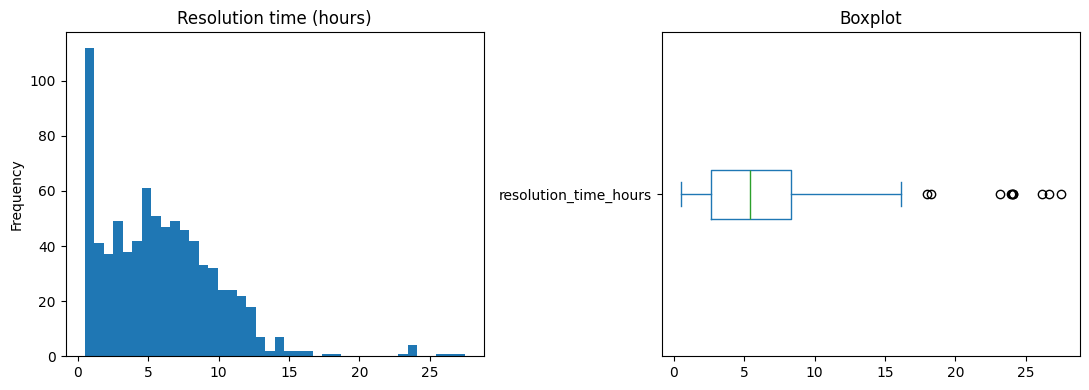

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
reg_df["resolution_time_hours"].plot(kind="hist", bins=40, ax=ax[0], title="Resolution time (hours)")
reg_df["resolution_time_hours"].plot(kind="box", vert=False, ax=ax[1], title="Boxplot")
plt.tight_layout()
plt.show()

**Regression data observations:**
- 800 tickets, same features as the classification data. Target: `resolution_time_hours`.
- Only numeric features have missing values.
- The target is right-skewed: most tickets resolve in under 11 hours, but a few take over 20. These are outliers.
- Many tickets sit exactly at 0.5 hours, which looks like a minimum cap.

## 2. Experiment A: Classification (predict `escalated`)

In [6]:
# Drop ticket_id (identifier) and separate the target
X = clf_df.drop(columns=["ticket_id", "escalated"])
y = clf_df["escalated"]

# Stratified split: the test set is held out and not touched until the end
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nEscalation rate (full): ", round(y.mean(), 3))
print("Escalation rate (train):", round(y_train.mean(), 3))
print("Escalation rate (test): ", round(y_test.mean(), 3))

Train: (720, 5) | Test: (180, 5)

Escalation rate (full):  0.212
Escalation rate (train): 0.212
Escalation rate (test):  0.211


In [7]:
numeric_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_cols = ["priority", "channel"]

In [8]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
])

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


**Split and preprocessing decisions:**
- `ticket_id` is dropped (identifier, no predictive meaning).
- 80/20 stratified split, so train and test both keep about 21% escalations.
- Numeric columns: median imputation (robust to outliers) then scaling (needed for k-NN and logistic regression).
- Categorical columns: most-frequent imputation then one-hot encoding (`handle_unknown="ignore"` avoids errors on unseen categories).
- Everything goes inside a Pipeline, so imputers, scaler and encoder are fitted only on training data.

### 2.1 Model comparison with 5-fold Stratified CV (primary metric: F1)

In [9]:
# Same folds for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "k-NN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

fold_scores = {}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1")
    fold_scores[name] = scores["test_score"]
    rows.append({
        "Model": name,
        "Mean F1": scores["test_score"].mean(),
        "Std F1": scores["test_score"].std(),
        "Min fold": scores["test_score"].min(),
        "Max fold": scores["test_score"].max(),
    })

cv_table = pd.DataFrame(rows).sort_values("Mean F1", ascending=False).round(3)
cv_table

,Model,Mean F1,Std F1,Min fold,Max fold
0,Logistic Regression,0.393,0.063,0.326,0.511
1,k-NN,0.361,0.050,0.286,0.426
2,Decision Tree,0.331,0.058,0.230,0.400


,Logistic Regression,k-NN,Decision Tree
Fold 1,0.391,0.367,0.400
Fold 2,0.326,0.326,0.230
Fold 3,0.364,0.426,0.323
Fold 4,0.372,0.286,0.373
Fold 5,0.511,0.400,0.328


C:\Users\ruham\AppData\Local\Temp\ipykernel_5840\2344084063.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(fold_scores.values(), labels=fold_scores.keys())


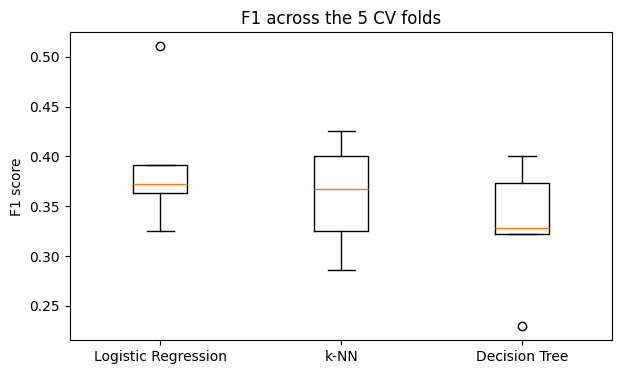

In [10]:
display(pd.DataFrame(fold_scores, index=[f"Fold {i}" for i in range(1, 6)]).round(3))

plt.figure(figsize=(7, 4))
plt.boxplot(fold_scores.values(), labels=fold_scores.keys())
plt.ylabel("F1 score")
plt.title("F1 across the 5 CV folds")
plt.show()

**CV comparison (F1, 5-fold StratifiedKFold, training set only):**
- Best mean F1: 0.393 (Logistic Regression), then k-NN 0.361, then Decision Tree 0.331.
- Most stable: k-NN (std 0.050). Least stable: Logistic Regression (std 0.063), driven by one high fold (0.511).
- Gaps between models (0.03 to 0.06) are about the size of the fold std, so the ranking is not strongly reliable.
- All scores are low. Always predicting "escalated" would give F1 ≈ 0.35 at a 21% escalation rate, so the features are only weakly predictive.
- The untuned decision tree likely overfits (no depth limit).
- Next: tune Logistic Regression (C and class_weight), since class imbalance likely hurts recall at the default 0.5 threshold.